# Laboratorio 2 – Pronóstico de caudal con FAformer (configuración optimizada)

Implementación de **FAformer** (Liu et al., *Knowledge-Based Systems* 332, 2025) adaptada al pronóstico de caudal: a partir de 336 horas (14 días) de 12 variables de una cuenca se predicen las siguientes 48 horas de caudal (`specific_discharge`, mm/h).

Este notebook **entrena desde cero y compara tres modelos** con los mejores parámetros encontrados en los estudios anteriores (búsqueda con validación en `FAformer.ipynb`):
1. **FAformer** optimizado (modelo completo del paper).
2. **FAformer w/o Flip**: ablación de la Tabla 3 del paper (el Flip-CI Encoder se reemplaza por el mismo mecanismo CD de la otra rama).
3. **RLinear**: baseline del paper (Tabla 2).

**Ejecución:** seleccionar el kernel *Python (GPU_env)* y ejecutar las celdas en orden (~1.5 h en GPU). Pesos, historiales, métricas y predicciones se guardan en `model_output_opt/`.

**Mejores parámetros (sin cambiar la arquitectura del paper)**
| Parámetro | Valor | Origen |
|---|---|---|
| σ (umbral del AEDB) | **0.5** | Sec. 6.6 del paper (rango 0.1–1.0); mejor MSE de validación entre {0.1, 0.2, 0.5, 0.8} |
| Normalización | Global por canal (estadísticos de train) | Mejor que la normalización por instancia en la búsqueda |
| Objetivo | Caudal (canal 11) | El objetivo de 12 variables no mejoró el MSE de validación |
| Optimización | Adam, lr 1e-3 → 1e-4 tras 5 épocas, batch 64, hasta 30 épocas, early stopping con paciencia 5 | Sec. 4.1 del paper |
| Parche / stride | 16 / 8 (parches solapados) | No especificado en el paper; mejor que 8/4 y 24/12 |
| d_model / d_ff / capas del encoder | 64 / 128 / 1 | No especificado; 128 y 2 capas no mejoraron |
| Dropout | **0.2** | No especificado; mejor que 0.1 |

**Componentes del paper implementados**
| Paper | Implementación |
|---|---|
| AEDB: DFT + selector Top-K adaptativo + máscara (Sec. 3.2, Ec. 1–4) | `AdaptiveEnergyDecompositionBlock` |
| Frequency RI Block + parches solapados (Ec. 5–6) | `FrequencyRIBlock` |
| Encoder local CD, tokens = canales (Ec. 7–9) | `EnergyBranch(mode="cd")` + `EncoderLayer` |
| Flip-CI Encoder, tokens = parches de cada canal (Ec. 13–15) | `EnergyBranch(mode="ci")` + `EncoderLayer` |
| Frequency Aggregation: `A' = Linear(P')` + IDFT al horizonte H (Ec. 10–12) | `EnergyBranch.head` + `irfft` |
| Suma de ramas (Ec. 16) | `FAformer.forward` |

**Adaptaciones al dataset y decisiones no especificadas en el paper**
- **Entradas:** las 12 variables históricas de `X`; `basin_id` solo se usa en el análisis por cuenca. `y_aux` no se usa.
- **Salida:** el modelo pronostica las 12 variables (como en el paper); se entrena, evalúa y entrega solo el caudal.
- **Horizonte:** ventana T = 336 y horizonte H = 48 (el paper usa L = 96 y H ∈ {96, 192, 336, 720}).
- **Normalización:** media y desviación por canal calculadas solo con train. Las predicciones se desnormalizan a mm/h y se recortan a ≥ 0, porque el caudal no puede ser negativo.
- **Pérdida:** MSE sobre el caudal normalizado.
- **DFT de señales reales:** `rfft`/`irfft` en el Frequency RI Block y en la reconstrucción (la misma DFT sin la mitad conjugada redundante).
- **Encoder Transformer:** atención de la Ec. 9 + residual + LayerNorm + FFN. Cada parche se proyecta S → M antes de la atención (equivale a W ∈ ℝ^{S×M} de la Ec. 9). En Flip-CI se añade un embedding posicional aprendible, porque los tokens son bandas de frecuencia ordenadas.
- **Métricas:** MSE y MAE (las del paper) y NSE (estándar en hidrología), en mm/h, y también MSE y MAE normalizados (la escala del paper).
- **Protocolo:** cada modelo se entrena con **3 semillas** y se reporta media ± desviación. La validación se usa para el early stopping; `test_targets.csv` se usa **solo en la evaluación final**.

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import json
import math
import random

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Configurar el dispositivo (GPU prioritaria para rapidez)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Ejecutando en: {device}")
if device.type == 'cuda':
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")

# Ruta base local
base_path = r'C:\Mis cosas\Deep Learning\laboratorio 2'
train_path = os.path.join(base_path, 'train.h5')
test_path = os.path.join(base_path, 'test.h5')
model_out_path = os.path.join(base_path, 'model_output_opt')

# Crear directorio para guardar modelos y resultados si no existe
os.makedirs(model_out_path, exist_ok=True)
print(f"Directorio de resultados listo en: {model_out_path}")

Ejecutando en: cuda
GPU detectada: NVIDIA GeForce RTX 5070 Ti
Directorio de resultados listo en: C:\Mis cosas\Deep Learning\laboratorio 2\model_output_opt


## 1. Carga de datos y preprocesamiento

- Se usa la partición provista por el dataset (`split`: 0 = train, 1 = validación).
- Los estadísticos de normalización se calculan **solo con train**, por bloques y en float64 (la presión ronda 93 500). La normalización se aplica sobre el mismo arreglo en float32 para no duplicar los ~4.4 GB de `X`.
- `y` (caudal futuro) se normaliza con los estadísticos del canal 11, de modo que entrada y objetivo quedan en la misma escala.

In [2]:
# Parámetros del proyecto
seq_len = 336        # Horas históricas
pred_len = 48        # Horas de pronóstico
channels = 12        # Número total de variables
target_channel = 11  # Índice de specific_discharge (caudal)
eval_batch_size = 512

with open(os.path.join(base_path, 'metadata.json'), encoding='utf-8') as f:
    channel_names = [c['name'] for c in json.load(f)['channels']]

print("Cargando datos desde archivos .h5...")
with h5py.File(train_path, 'r') as f:
    X_full = f['X'][:]            # [N, 336, 12]
    y_full = f['y'][:]            # [N, 48] caudal futuro en mm/h
    split_info = f['split'][:]    # 0 = train, 1 = validación
    basin_full = f['basin_id'][:]

with h5py.File(test_path, 'r') as f:
    X_test = f['X'][:]            # [N_test, 336, 12] (sin 'y')
    basin_test = f['basin_id'][:]

train_idx = np.flatnonzero(split_info == 0)
val_idx = np.flatnonzero(split_info == 1)
print(f"Muestras de Entrenamiento: {len(train_idx)}")
print(f"Muestras de Validación: {len(val_idx)}")
print(f"Muestras de Test: {len(X_test)}")


def channel_stats(X, idx, chunk=10000):
    """Media y desviación estándar por canal sobre las muestras idx (en bloques, float64)."""
    shift = X[idx[:chunk]].reshape(-1, X.shape[-1]).mean(axis=0, dtype=np.float64)
    s = np.zeros(X.shape[-1])
    s2 = np.zeros(X.shape[-1])
    n = 0
    for i in range(0, len(idx), chunk):
        block = X[idx[i:i + chunk]].reshape(-1, X.shape[-1]).astype(np.float64) - shift
        s += block.sum(axis=0)
        s2 += (block ** 2).sum(axis=0)
        n += block.shape[0]
    mean = shift + s / n
    std = np.sqrt(s2 / n - (s / n) ** 2)
    return mean.astype(np.float32), std.astype(np.float32)


# Normalización de X (estadísticos solo de train)
x_mean, x_std = channel_stats(X_full, train_idx)
X_full -= x_mean
X_full /= x_std
X_test -= x_mean
X_test /= x_std

# Normalización del objetivo con los estadísticos del canal de caudal
q_mean, q_std = float(x_mean[target_channel]), float(x_std[target_channel])
y_norm = (y_full - q_mean) / q_std
print(f"Caudal (canal {target_channel}): media = {q_mean:.4f} mm/h, std = {q_std:.4f} mm/h")

# Tensores que comparten memoria con los arreglos numpy
X_full_t = torch.from_numpy(X_full)
y_norm_t = torch.from_numpy(y_norm)
X_test_t = torch.from_numpy(X_test)

# Valores observados de validación en mm/h (para métricas y análisis)
y_val_mmh = y_full[val_idx]
basin_val = basin_full[val_idx]


class ArrayLoader:
    """Itera por lotes indexando directamente los tensores, sin copiar train/val en memoria."""
    def __init__(self, X, y, idx, batch_size, shuffle=False, seed=SEED):
        self.X, self.y = X, y
        self.idx = torch.as_tensor(idx, dtype=torch.long)
        self.batch_size, self.shuffle = batch_size, shuffle
        self.gen = torch.Generator().manual_seed(seed)

    def __len__(self):
        return math.ceil(len(self.idx) / self.batch_size)

    def __iter__(self):
        order = self.idx[torch.randperm(len(self.idx), generator=self.gen)] if self.shuffle else self.idx
        for start in range(0, len(order), self.batch_size):
            b = order[start:start + self.batch_size]
            yield (self.X[b],) if self.y is None else (self.X[b], self.y[b])


# Loaders de evaluación (el de entrenamiento se crea en train_model con la semilla de cada corrida)
val_loader = ArrayLoader(X_full_t, y_norm_t, val_idx, eval_batch_size)
test_loader = ArrayLoader(X_test_t, None, np.arange(len(X_test)), eval_batch_size)

Cargando datos desde archivos .h5...
Muestras de Entrenamiento: 254000
Muestras de Validación: 18142
Muestras de Test: 27983
Caudal (canal 11): media = 0.0671 mm/h, std = 0.1621 mm/h


## 2. Modelos

**FAformer** (entrada `[B, T=336, C=12]`, salida `[B, H=48, C=12]`):
1. **AEDB:** DFT por muestra y variable; se conservan las frecuencias con amplitud ≥ media − σ (Top-K adaptativo, Ec. 2). Su IDFT es `X_high` y el residuo es `X_low` (Ec. 3–4).
2. **Frequency RI Block:** DFT de cada componente, separación en parte real e imaginaria y parches solapados sobre el eje de frecuencia → `[B, C, N, S]`.
3. **Rama de alta energía (CD):** en cada parche, los 12 canales son los tokens; la atención captura relaciones entre variables.
4. **Rama de baja energía (Flip-CI):** en cada canal, los N parches son los tokens; no hay mezcla entre variables.
5. **Frequency Aggregation:** se concatenan las salidas de los N parches y una capa lineal las proyecta al espectro del horizonte (H/2 + 1 bins, parte real e imaginaria); `irfft` lo lleva a 48 horas.
6. **Predicción:** suma de ambas ramas (Ec. 16).

**FAformer w/o Flip (ablación, Tabla 3):** igual al anterior, pero la rama de baja energía usa el mismo mecanismo CD que la de alta (`low_mode="cd"`, con pesos propios).

**RLinear (baseline, Tabla 2):** RevIN + una capa lineal 336 → 48 compartida entre canales.

In [3]:
# --- Baseline ---
class RevIN(nn.Module):
    """Reversible Instance Normalization (Kim et al., 2021), usada por RLinear."""
    def __init__(self, num_features, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))

    def normalize(self, x):                                  # x: [B, T, C]
        self.mean = x.mean(dim=1, keepdim=True).detach()
        self.std = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
        return (x - self.mean) / self.std * self.weight + self.bias

    def denormalize(self, y):                                # y: [B, H, C]
        y = (y - self.bias) / (self.weight + self.eps ** 2)
        return y * self.std + self.mean


class RLinear(nn.Module):
    """Baseline del paper (Tabla 2): RevIN + capa lineal T -> H compartida entre canales."""
    def __init__(self, seq_len, pred_len, channels):
        super().__init__()
        self.revin = RevIN(channels)
        self.linear = nn.Linear(seq_len, pred_len)

    def forward(self, x):                                    # -> [B, H, C]
        x = self.revin.normalize(x)
        out = self.linear(x.transpose(1, 2)).transpose(1, 2)
        return self.revin.denormalize(out)


# --- FAformer ---
class AdaptiveEnergyDecompositionBlock(nn.Module):
    """AEDB (Sec. 3.2, Ec. 1-4): separa cada variable de cada muestra en componentes de alta y baja energía."""
    def __init__(self, sigma=0.8):
        super().__init__()
        self.sigma = sigma

    def forward(self, x):                                    # x: [B, T, C]
        Z = torch.fft.fft(x, dim=1)                          # Ec. 1
        amp = Z.abs()
        threshold = amp.mean(dim=1, keepdim=True) - self.sigma   # Ec. 2: media por muestra y variable menos σ
        mask = (amp >= threshold).to(x.dtype)                # Top-K adaptativo: K = nº de frecuencias sobre el umbral
        x_high = torch.fft.ifft(Z * mask, dim=1).real        # Ec. 3
        return x_high, x - x_high                            # Ec. 4


class FrequencyRIBlock(nn.Module):
    """Ec. 5-6: DFT, separación real/imaginaria y parches solapados sobre el eje de frecuencia."""
    def __init__(self, seq_len, patch_len, stride):
        super().__init__()
        self.patch_len, self.stride = patch_len, stride
        n_freq = seq_len // 2 + 1                                              # 169 bins para T = 336
        self.n_patches = math.ceil(max(n_freq - patch_len, 0) / stride) + 1    # 21 parches
        self.pad = (self.n_patches - 1) * stride + patch_len - n_freq          # relleno para cubrir todos los bins

    def forward(self, x):                                    # x: [B, T, C]
        A = torch.fft.rfft(x, dim=1).permute(0, 2, 1)        # [B, C, F]
        R = F.pad(A.real, (0, self.pad)).unfold(-1, self.patch_len, self.stride)   # [B, C, N, S]
        I = F.pad(A.imag, (0, self.pad)).unfold(-1, self.patch_len, self.stride)
        return R, I


class EncoderLayer(nn.Module):
    """Encoder Transformer: atención (Ec. 9) + residual + LayerNorm + FFN."""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, h):                                    # h: [..., tokens, d_model]
        Q, K, V = self.W_q(h), self.W_k(h), self.W_v(h)
        attn = torch.softmax(Q @ K.transpose(-1, -2) / Q.size(-1) ** 0.5, dim=-1)
        h = self.norm1(h + self.drop(attn @ V))
        return self.norm2(h + self.drop(self.ffn(h)))


class EnergyBranch(nn.Module):
    """Rama CD (Sec. 3.3, tokens = canales) o Flip-CI (Sec. 3.4, tokens = parches) + Frequency Aggregation (Ec. 10-12)."""
    def __init__(self, mode, n_patches, patch_len, d_model, d_ff, n_layers, pred_len, dropout=0.1):
        super().__init__()
        assert mode in ("cd", "ci")
        self.mode, self.pred_len = mode, pred_len
        self.n_out = pred_len // 2 + 1                                    # 25 bins para H = 48
        self.embed = nn.Linear(patch_len, d_model)                        # proyección S -> M
        self.pos = nn.Parameter(torch.zeros(n_patches, d_model)) if mode == "ci" else None
        self.encoder = nn.ModuleList([EncoderLayer(d_model, d_ff, dropout) for _ in range(n_layers)])
        self.head = nn.Linear(2 * n_patches * d_model, 2 * self.n_out)    # Ec. 11: A' = Linear(P')

    def encode(self, P):                                     # P: [B, C, N, S]
        h = self.embed(P)
        if self.mode == "cd":
            h = h.transpose(1, 2)                            # [B, N, C, M]: atención entre canales dentro de cada parche
            for layer in self.encoder:
                h = layer(h)
            h = h.transpose(1, 2)
        else:
            h = h + self.pos                                 # [B, C, N, M]: atención entre parches dentro de cada canal
            for layer in self.encoder:
                h = layer(h)
        return h.flatten(-2)                                 # [B, C, N*M]

    def forward(self, R, I):
        z = self.head(torch.cat([self.encode(R), self.encode(I)], dim=-1))     # [B, C, 2*n_out]
        A_out = torch.complex(z[..., :self.n_out], z[..., self.n_out:])
        return torch.fft.irfft(A_out, n=self.pred_len, dim=-1).transpose(1, 2)  # Ec. 12 -> [B, H, C]


class FAformer(nn.Module):
    """FAformer (Fig. 2). low_mode="cd" reemplaza Flip-CI por atención CD (ablación 'w/o Flip', Tabla 3)."""
    def __init__(self, seq_len, pred_len, patch_len=16, stride=8, d_model=64, d_ff=128, n_layers=1,
                 sigma=0.8, dropout=0.1, low_mode="ci"):
        super().__init__()
        self.aedb = AdaptiveEnergyDecompositionBlock(sigma)
        self.freq_ri = FrequencyRIBlock(seq_len, patch_len, stride)
        n = self.freq_ri.n_patches
        self.high = EnergyBranch("cd", n, patch_len, d_model, d_ff, n_layers, pred_len, dropout)
        self.low = EnergyBranch(low_mode, n, patch_len, d_model, d_ff, n_layers, pred_len, dropout)

    def forward(self, x):                                    # x: [B, T, C] -> [B, H, C]
        x_high, x_low = self.aedb(x)
        return self.high(*self.freq_ri(x_high)) + self.low(*self.freq_ri(x_low))   # Ec. 16


# Mejores parámetros (búsqueda con validación en FAformer.ipynb)
BEST_PARAMS = {'sigma': 0.5, 'patch_len': 16, 'stride': 8, 'd_model': 64, 'd_ff': 128, 'n_layers': 1, 'dropout': 0.2}
BATCH_SIZE = 64


def build_model(name):
    if name == 'FAformer':
        return FAformer(seq_len, pred_len, low_mode="ci", **BEST_PARAMS)
    if name == 'FAformer w/o Flip':
        return FAformer(seq_len, pred_len, low_mode="cd", **BEST_PARAMS)
    if name == 'RLinear (baseline)':
        return RLinear(seq_len, pred_len, channels)
    raise ValueError(name)


MODELS = ['FAformer', 'FAformer w/o Flip', 'RLinear (baseline)']
colors = {'FAformer': 'blue', 'FAformer w/o Flip': 'orange', 'RLinear (baseline)': 'red'}

print("Mejores parámetros:", BEST_PARAMS, "| batch:", BATCH_SIZE)
for name in MODELS:
    print(f"Parámetros {name:20s}: {sum(p.numel() for p in build_model(name).parameters()):,}")

Mejores parámetros: {'sigma': 0.5, 'patch_len': 16, 'stride': 8, 'd_model': 64, 'd_ff': 128, 'n_layers': 1, 'dropout': 0.2} | batch: 64
Parámetros FAformer            : 331,044
Parámetros FAformer w/o Flip   : 329,700
Parámetros RLinear (baseline)  : 16,200


## 3. Entrenamiento: funciones comunes

- **Esquema del paper (Sec. 4.1):** Adam con lr 1e-3 reducido a 1e-4 después de 5 épocas, hasta 30 épocas.
- **Early stopping** con paciencia 5 sobre el MSE de validación del caudal; se conserva el mejor checkpoint.
- **Pérdida:** MSE sobre el caudal normalizado.
- Modelos con la misma semilla ven los lotes en el mismo orden (comparación justa).

In [4]:
epochs = 30
patience = 5
learning_rate_init = 1e-3


def predict(model, loader):
    """Predicciones de caudal en mm/h: desnormalizadas y recortadas a caudal >= 0."""
    model.eval()
    preds = []
    with torch.no_grad():
        for batch in loader:
            preds.append(model(batch[0].to(device, non_blocking=True))[:, :, target_channel].cpu())
    pred = torch.cat(preds).numpy() * q_std + q_mean
    return np.clip(pred, 0.0, None)


def compute_metrics(pred, obs):
    """MSE y MAE (métricas del paper) y NSE (Nash-Sutcliffe) sobre todo el conjunto, en mm/h.
    MSE_norm y MAE_norm: las mismas métricas en la escala normalizada del caudal (la escala del paper)."""
    obs = obs.astype(np.float64)
    err = pred.astype(np.float64) - obs
    mse, mae = float(np.mean(err ** 2)), float(np.mean(np.abs(err)))
    return {'MSE': mse,
            'MAE': mae,
            'NSE': float(1 - np.sum(err ** 2) / np.sum((obs - obs.mean()) ** 2)),
            'MSE_norm': mse / q_std ** 2,
            'MAE_norm': mae / q_std}


def train_model(name, seed):
    """Entrena desde cero con early stopping y devuelve (modelo con los mejores pesos, historial)."""
    tag = f"{name.split(' (')[0].replace(' ', '_').replace('/', '')}_s{seed}"
    ckpt_path = os.path.join(model_out_path, f'best_{tag}.pth')

    torch.manual_seed(seed)
    model = build_model(name).to(device)
    loader = ArrayLoader(X_full_t, y_norm_t, train_idx, BATCH_SIZE, shuffle=True, seed=seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate_init)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[5], gamma=0.1)   # 1e-3 -> 1e-4
    criterion = nn.MSELoss()
    best_val, wait, history = float('inf'), 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        total, n = 0.0, 0
        current_lr = optimizer.param_groups[0]['lr']
        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)
            loss = criterion(model(batch_x)[:, :, target_channel], batch_y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch_x)
            n += len(batch_x)
        scheduler.step()

        val = compute_metrics(predict(model, val_loader), y_val_mmh)
        history.append({'epoch': epoch, 'lr': current_lr, 'train_loss_norm': total / n,
                        **{f'val_{k}': v for k, v in val.items()}})
        print(f"[{tag}] Época {epoch:2d}/{epochs} | lr {current_lr:.0e} | Train MSE (norm) {total / n:.4f} | "
              f"Val MSE {val['MSE']:.5f} | MAE {val['MAE']:.4f} | NSE {val['NSE']:.4f}")

        if val['MSE'] < best_val:
            best_val, wait = val['MSE'], 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑 [{tag}] Early stopping en la época {epoch}: {patience} épocas sin mejorar.")
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    hist = pd.DataFrame(history)
    hist.to_csv(os.path.join(model_out_path, f'historial_{tag}.csv'), index=False)
    print(f"✅ [{tag}] Mejor Val MSE: {best_val:.5f} mm²/h²\n")
    return model, hist

## 4. Entrenamiento (3 modelos × 3 semillas)

Se entrenan desde cero el **FAformer**, el **FAformer w/o Flip** y el **RLinear**, cada uno con las semillas 42, 43 y 44. Las métricas se reportan como media ± desviación entre semillas; los gráficos usan la semilla con mejor MSE de validación de cada modelo.

===== FAformer | semilla 42 =====
[FAformer_s42] Época  1/30 | lr 1e-03 | Train MSE (norm) 0.5308 | Val MSE 0.01383 | MAE 0.0395 | NSE 0.5301
[FAformer_s42] Época  2/30 | lr 1e-03 | Train MSE (norm) 0.4924 | Val MSE 0.01322 | MAE 0.0359 | NSE 0.5511
[FAformer_s42] Época  3/30 | lr 1e-03 | Train MSE (norm) 0.4823 | Val MSE 0.01292 | MAE 0.0369 | NSE 0.5611
[FAformer_s42] Época  4/30 | lr 1e-03 | Train MSE (norm) 0.4745 | Val MSE 0.01290 | MAE 0.0363 | NSE 0.5618
[FAformer_s42] Época  5/30 | lr 1e-03 | Train MSE (norm) 0.4663 | Val MSE 0.01262 | MAE 0.0312 | NSE 0.5712
[FAformer_s42] Época  6/30 | lr 1e-04 | Train MSE (norm) 0.4426 | Val MSE 0.01232 | MAE 0.0348 | NSE 0.5815
[FAformer_s42] Época  7/30 | lr 1e-04 | Train MSE (norm) 0.4368 | Val MSE 0.01222 | MAE 0.0324 | NSE 0.5850
[FAformer_s42] Época  8/30 | lr 1e-04 | Train MSE (norm) 0.4336 | Val MSE 0.01204 | MAE 0.0306 | NSE 0.5910
[FAformer_s42] Época  9/30 | lr 1e-04 | Train MSE (norm) 0.4316 | Val MSE 0.01202 | MAE 0.0309 | NSE 0

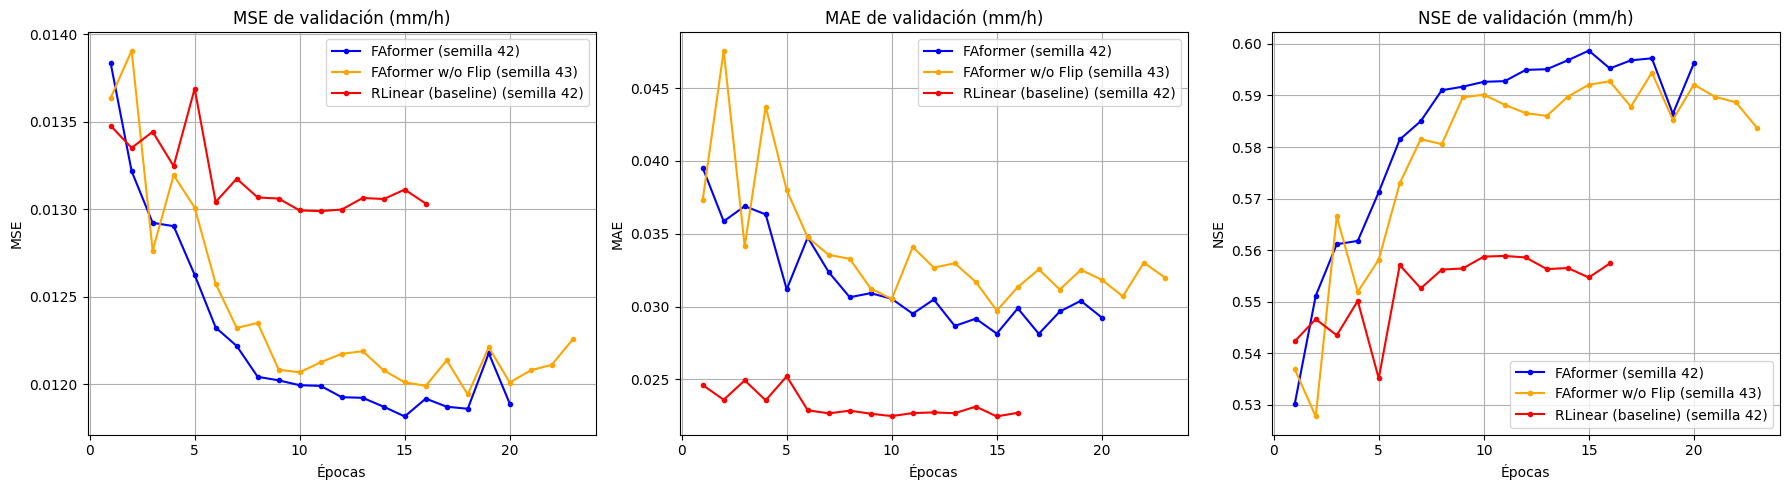

In [5]:
SEEDS = [42, 43, 44]

runs = {}
for name in MODELS:
    runs[name] = []
    for seed in SEEDS:
        print(f"===== {name} | semilla {seed} =====")
        model, hist = train_model(name, seed)
        runs[name].append({'seed': seed, 'model': model, 'hist': hist})

best_runs = {name: min(r, key=lambda run: run['hist']['val_MSE'].min()) for name, r in runs.items()}
best_models = {name: run['model'] for name, run in best_runs.items()}
print("Semilla elegida por modelo:", {name: run['seed'] for name, run in best_runs.items()})

# Curvas de validación (semilla elegida)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['MSE', 'MAE', 'NSE']):
    for name, run in best_runs.items():
        ax.plot(run['hist']['epoch'], run['hist'][f'val_{metric}'], label=f"{name} (semilla {run['seed']})",
                color=colors[name], marker='o', markersize=3)
    ax.set_title(f'{metric} de validación (mm/h)')
    ax.set_xlabel('Épocas')
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 5. Resultados en validación

Media ± desviación entre las 3 semillas de cada modelo.

Métricas de validación (media ± desviación entre semillas; MSE/MAE/NSE en mm/h):


,MSE,MAE,NSE,MSE_norm,MAE_norm
modelo,,,,,
FAformer,0.01196 ± 0.00013,0.02857 ± 0.00140,0.59397 ± 0.00429,0.45523 ± 0.00481,0.17627 ± 0.00866
FAformer w/o Flip,0.01199 ± 0.00007,0.02983 ± 0.00157,0.59273 ± 0.00253,0.45661 ± 0.00284,0.18406 ± 0.00971
RLinear (baseline),0.01301 ± 0.00002,0.02273 ± 0.00003,0.55807 ± 0.00079,0.49548 ± 0.00088,0.14025 ± 0.00020


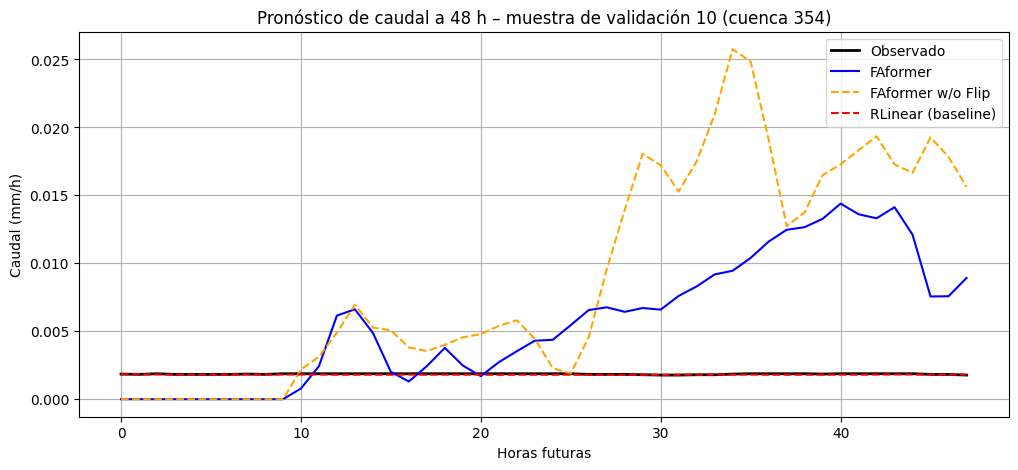

In [6]:
metric_names = ['MSE', 'MAE', 'NSE', 'MSE_norm', 'MAE_norm']


def per_seed_metrics(loader, obs):
    """Métricas de cada semilla de cada modelo (DataFrame largo)."""
    rows = []
    for name, rs in runs.items():
        for r in rs:
            rows.append({'modelo': name, 'semilla': r['seed'], **compute_metrics(predict(r['model'], loader), obs)})
    return pd.DataFrame(rows)


def summarize(df_long):
    """Media ± desviación entre semillas, en el orden de MODELS."""
    agg = df_long.groupby('modelo', sort=False)[metric_names].agg(['mean', 'std'])
    table = pd.DataFrame({m: [f"{agg.loc[n, (m, 'mean')]:.5f} ± {agg.loc[n, (m, 'std')]:.5f}" for n in agg.index]
                          for m in metric_names}, index=agg.index)
    return agg, table


val_long = per_seed_metrics(val_loader, y_val_mmh)
val_long.to_csv(os.path.join(model_out_path, 'metricas_validacion_semillas.csv'), index=False)
val_agg, val_table = summarize(val_long)
val_table.to_csv(os.path.join(model_out_path, 'metricas_validacion.csv'))
pred_val = {name: predict(m, val_loader) for name, m in best_models.items()}
print("Métricas de validación (media ± desviación entre semillas; MSE/MAE/NSE en mm/h):")
display(val_table)

# Ejemplo de pronóstico en validación
sample_idx = 10  # Cambia el índice para inspeccionar otras muestras
plt.figure(figsize=(12, 5))
plt.plot(y_val_mmh[sample_idx], label='Observado', color='black', linewidth=2)
for name, p in pred_val.items():
    plt.plot(p[sample_idx], label=name, color=colors[name], linestyle='-' if name == 'FAformer' else '--')
plt.title(f'Pronóstico de caudal a 48 h – muestra de validación {sample_idx} (cuenca {basin_val[sample_idx]})')
plt.xlabel('Horas futuras')
plt.ylabel('Caudal (mm/h)')
plt.legend()
plt.grid(True)
plt.show()

## 6. Estudio de ablación: "w/o Flip" (Tabla 3 del paper)

Se compara el FAformer completo con la versión sin Flip-CI. Una diferencia se considera clara solo si supera la variación entre semillas (|Δ media| > desv. completo + desv. ablación). El gráfico muestra la curva de validación de la semilla elegida de cada modelo, con el baseline como referencia.

--- CONCLUSIÓN ABLACIÓN (validación) ---
Δ = w/o Flip − FAformer completo (MSE y MAE: positivo = la ablación es peor; NSE: negativo = peor)


,Δ MSE,MSE: ¿clara?,Δ MAE,MAE: ¿clara?,Δ NSE,NSE: ¿clara?
FAformer w/o Flip,+0.30 %,no (dentro del ruido),+4.42 %,no (dentro del ruido),-0.0012,no (dentro del ruido)


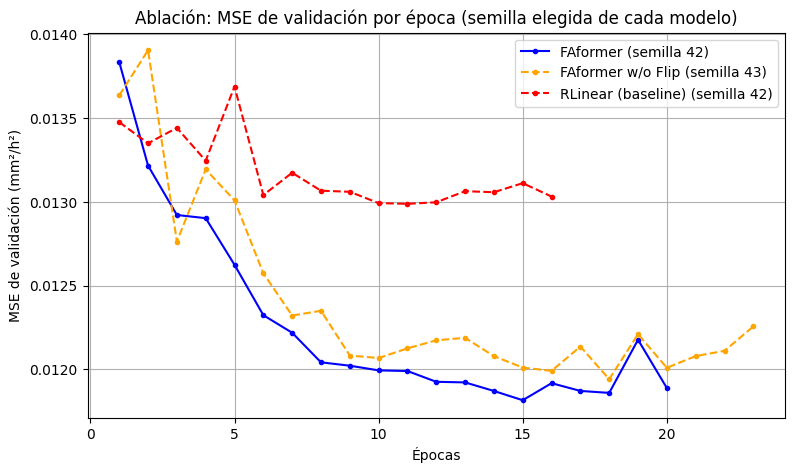

In [7]:
def ablation_table(agg):
    full, abl = agg.loc['FAformer'], agg.loc['FAformer w/o Flip']
    row = {}
    for m in ['MSE', 'MAE', 'NSE']:
        diff = abl[(m, 'mean')] - full[(m, 'mean')]
        noise = abl[(m, 'std')] + full[(m, 'std')]
        row[f'Δ {m}'] = f"{diff / full[(m, 'mean')] * 100:+.2f} %" if m != 'NSE' else f"{diff:+.4f}"
        row[f'{m}: ¿clara?'] = 'sí' if abs(diff) > noise else 'no (dentro del ruido)'
    return pd.DataFrame({'FAformer w/o Flip': row}).T


print("--- CONCLUSIÓN ABLACIÓN (validación) ---")
print("Δ = w/o Flip − FAformer completo (MSE y MAE: positivo = la ablación es peor; NSE: negativo = peor)")
abl_val = ablation_table(val_agg)
abl_val.to_csv(os.path.join(model_out_path, 'ablacion_validacion.csv'))
display(abl_val)

plt.figure(figsize=(9, 5))
for name, run in best_runs.items():
    plt.plot(run['hist']['epoch'], run['hist']['val_MSE'], color=colors[name], marker='o', markersize=3,
             linestyle='-' if name == 'FAformer' else '--', label=f"{name} (semilla {run['seed']})")
plt.title('Ablación: MSE de validación por época (semilla elegida de cada modelo)')
plt.xlabel('Épocas')
plt.ylabel('MSE de validación (mm²/h²)')
plt.legend()
plt.grid(True)
plt.show()

## 7. Análisis de errores (validación)

La función `error_analysis` se aplica aquí a validación y en la sección 10 al conjunto de test:
- **Error por horizonte:** cómo crecen el MAE y el sesgo a medida que se pronostica más lejos.
- **NSE por cuenca:** en qué cuencas el modelo funciona bien o mal.
- **Error según la magnitud del caudal:** comportamiento en caudales bajos y en picos (crecidas).

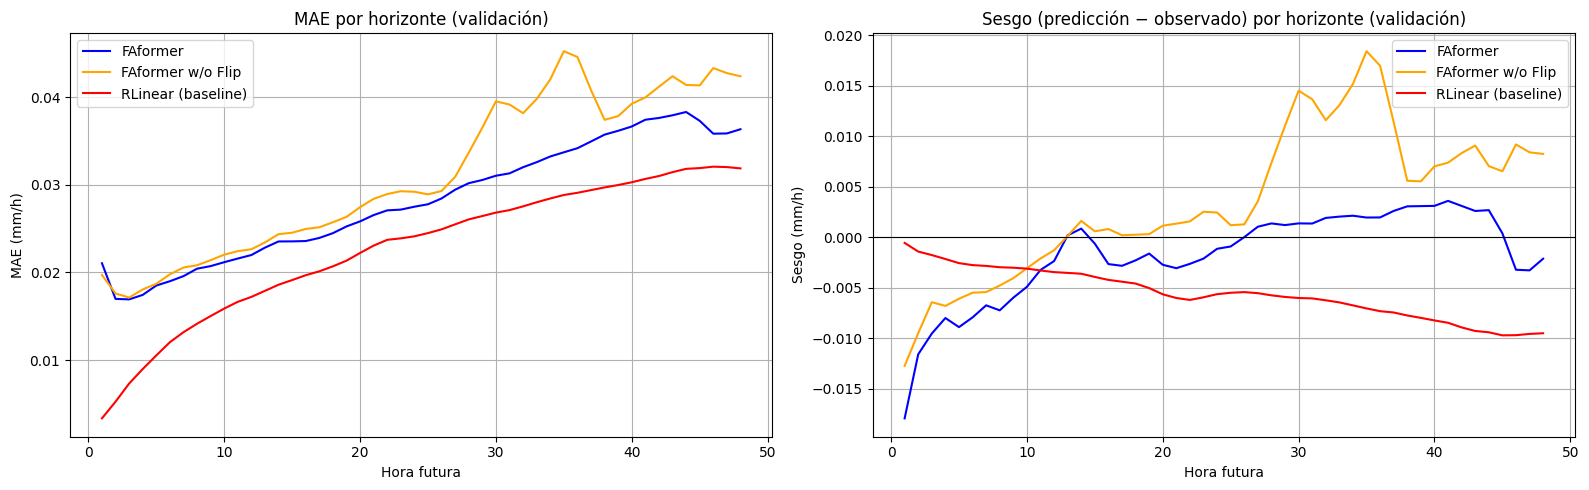

Cuencas evaluadas en validación (≥ 10 muestras): 508
NSE por cuenca (la mediana es más representativa que la media, sensible a cuencas de caudal casi constante):


,25%,50%,75%,cuencas con NSE < −1
FAformer,0.0700,0.4742,0.7302,54
FAformer w/o Flip,0.0261,0.4074,0.6947,55
RLinear (baseline),0.2736,0.5886,0.8065,10


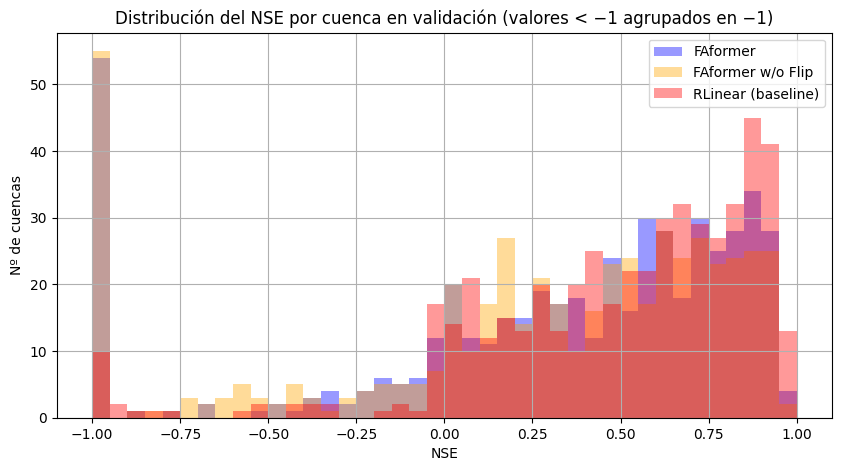

Cuencas con peor NSE para FAformer (validación):


,FAformer,FAformer w/o Flip,RLinear (baseline)
369,-37035.3448,-243149.2499,-3.0946
377,-32673.3461,-47692.4070,-433.6432
301,-18328.1287,-34130.9051,0.4108
188,-13733.5262,-45815.8479,0.7422
17,-5875.1334,-31221.7405,0.8507
378,-1511.1631,-2894.9536,0.3909
357,-810.3069,-2186.3309,0.3647
135,-483.9254,-755.4326,-0.3748
380,-449.9155,-558.0683,0.9198
404,-191.4865,-466.6070,0.5178


Error por rango de caudal observado en validación (mm/h):


,MAE < p50,MAE p50–p90,MAE p90–p99,MAE > p99 (picos),Sesgo < p50,Sesgo p50–p90,Sesgo p90–p99,Sesgo > p99 (picos)
FAformer,0.0087,0.0235,0.0899,0.6271,0.0031,0.0084,-0.0153,-0.5269
FAformer w/o Flip,0.0119,0.0271,0.0898,0.6291,0.0073,0.0145,-0.0081,-0.5256
RLinear (baseline),0.0021,0.0157,0.0959,0.6727,0.0013,0.0044,-0.0263,-0.5592


In [8]:
def nse_by_basin(pred, obs, basins, min_samples=10):
    """NSE por cuenca; se omiten cuencas con pocas muestras (el denominador es inestable)."""
    out = {}
    for b in np.unique(basins):
        m = basins == b
        if m.sum() < min_samples:
            continue
        o = obs[m].astype(np.float64)
        denom = np.sum((o - o.mean()) ** 2)
        if denom > 0:
            out[b] = 1 - np.sum((pred[m] - o) ** 2) / denom
    return pd.Series(out)


def error_analysis(preds, obs, basins, split_name):
    """Error por horizonte, NSE por cuenca y error según la magnitud del caudal (todo en mm/h)."""
    # 1) Error por horizonte
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for name, p in preds.items():
        err = p - obs
        axes[0].plot(range(1, pred_len + 1), np.mean(np.abs(err), axis=0), label=name, color=colors[name])
        axes[1].plot(range(1, pred_len + 1), np.mean(err, axis=0), label=name, color=colors[name])
    axes[0].set_title(f'MAE por horizonte ({split_name})')
    axes[0].set_ylabel('MAE (mm/h)')
    axes[1].set_title(f'Sesgo (predicción − observado) por horizonte ({split_name})')
    axes[1].set_ylabel('Sesgo (mm/h)')
    axes[1].axhline(0, color='black', linewidth=0.8)
    for ax in axes:
        ax.set_xlabel('Hora futura')
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()

    # 2) NSE por cuenca
    nse_basin = pd.DataFrame({name: nse_by_basin(p, obs, basins) for name, p in preds.items()})
    print(f"Cuencas evaluadas en {split_name} (≥ 10 muestras): {len(nse_basin)}")
    summary = nse_basin.describe().T[['25%', '50%', '75%']]
    summary['cuencas con NSE < −1'] = (nse_basin < -1).sum()
    print("NSE por cuenca (la mediana es más representativa que la media, sensible a cuencas de caudal casi constante):")
    display(summary.style.format({'25%': '{:.4f}', '50%': '{:.4f}', '75%': '{:.4f}'}))

    plt.figure(figsize=(10, 5))
    bins = np.linspace(-1, 1, 41)
    for name in preds:
        plt.hist(nse_basin[name].clip(-1, 1), bins=bins, alpha=0.4, label=name, color=colors[name])
    plt.title(f'Distribución del NSE por cuenca en {split_name} (valores < −1 agrupados en −1)')
    plt.xlabel('NSE')
    plt.ylabel('Nº de cuencas')
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"Cuencas con peor NSE para FAformer ({split_name}):")
    display(nse_basin.sort_values('FAformer').head(10).style.format('{:.4f}'))

    # 3) Error según la magnitud del caudal observado (percentiles del propio conjunto)
    q_edges = np.quantile(obs, [0.5, 0.9, 0.99])
    q_labels = ['< p50', 'p50–p90', 'p90–p99', '> p99 (picos)']
    q_bin = np.digitize(obs, q_edges)
    rows = {}
    for name, p in preds.items():
        err = p - obs
        rows[name] = {f'MAE {lab}': np.mean(np.abs(err[q_bin == k])) for k, lab in enumerate(q_labels)}
        rows[name].update({f'Sesgo {lab}': np.mean(err[q_bin == k]) for k, lab in enumerate(q_labels)})
    df_ranges = pd.DataFrame(rows).T
    print(f"Error por rango de caudal observado en {split_name} (mm/h):")
    display(df_ranges.style.format('{:.4f}'))
    return nse_basin, df_ranges


nse_basin_val, rangos_val = error_analysis(pred_val, y_val_mmh, basin_val, 'validación')

## 8. Descomposición AEDB en los datos (Sec. 6.4 y 6.6 del paper)

- **HEFR / HER por variable** con σ = 0.5: fracción de frecuencias (Ec. 17) y de energía (Tabla 12) asignadas a la componente de alta energía, y porcentaje de ventanas que el AEDB no descompone (todas las frecuencias quedan en la componente de alta energía y `X_low` = 0).
- **Sensibilidad a σ.** Referencia del paper (Tabla 12): HEFR entre 10.8 % y 24.1 %.

In [9]:
def aedb_stats(x, sigma):
    amp = torch.fft.fft(x, dim=1).abs()
    mask = amp >= amp.mean(dim=1, keepdim=True) - sigma
    hefr = mask.float().mean(dim=1).mean(dim=0) * 100
    her = ((amp ** 2 * mask).sum(dim=1) / (amp ** 2).sum(dim=1).clamp_min(1e-12)).mean(dim=0) * 100
    undecomposed = mask.all(dim=1).float().mean(dim=0) * 100
    return hefr.cpu().numpy(), her.cpu().numpy(), undecomposed.cpu().numpy()


with torch.no_grad():
    xb = X_full_t[torch.as_tensor(val_idx[::4])].to(device)
    hefr, her, und = aedb_stats(xb, BEST_PARAMS['sigma'])
    print(f"AEDB con σ = {BEST_PARAMS['sigma']}:")
    display(pd.DataFrame({'HEFR (% frecuencias)': hefr, 'HER (% energía)': her, '% ventanas sin descomponer': und},
                         index=channel_names).style.format('{:.2f}'))

    rows = []
    for s in (0.1, 0.2, 0.5, 0.8, 1.0):
        h, _, u = aedb_stats(xb, s)
        rows.append({'σ': s, 'HEFR caudal %': h[target_channel], '% ventanas sin descomponer (caudal)': u[target_channel],
                     'HEFR medio %': h.mean(), 'variables con HEFR 10–25 %': int(((h >= 10) & (h <= 25)).sum())})
    print("Sensibilidad del AEDB a σ:")
    display(pd.DataFrame(rows).style.format({'HEFR caudal %': '{:.1f}', '% ventanas sin descomponer (caudal)': '{:.1f}',
                                             'HEFR medio %': '{:.1f}'}))

AEDB con σ = 0.5:


,HEFR (% frecuencias),HER (% energía),% ventanas sin descomponer
convective_fraction,41.45,91.17,7.63
longwave_radiation,17.76,98.78,0.00
potential_energy,34.45,99.50,8.66
potential_evaporation,19.52,99.13,0.00
pressure,32.13,99.99,17.86
shortwave_radiation,19.31,99.46,0.00
specific_humidity,15.45,99.69,0.00
temperature,14.97,99.72,0.00
total_precipitation,44.85,89.23,6.13
wind_u,19.43,99.11,0.00


Sensibilidad del AEDB a σ:


,σ,HEFR caudal %,% ventanas sin descomponer (caudal),HEFR medio %,variables con HEFR 10–25 %
0,0.100000,10.3,0.0,18.1,9
1,0.200000,12.2,0.2,19.3,10
2,0.500000,60.1,45.8,28.2,7
3,0.800000,71.4,61.2,33.9,7
4,1.000000,74.8,66.0,36.7,7


## 9. Predicciones en el conjunto de test

Se generan las predicciones para las 27 983 muestras de `test.h5` con la semilla elegida de cada modelo. Cada CSV usa el mismo formato que `test_targets.csv`: `Id` (índice de fila en `test.h5`, según `metadata.json`) y `q_01 … q_48`, el caudal pronosticado en mm/h. El archivo para entregar es `FAformer_Test_Predictions.csv`.

Ejecutando inferencia en el conjunto de Test...
Formato final de predicciones FAformer Test: (27983, 48) [Muestras, 48 Horas]
✅ Predicciones exportadas a CSV en el directorio: C:\Mis cosas\Deep Learning\laboratorio 2\model_output_opt


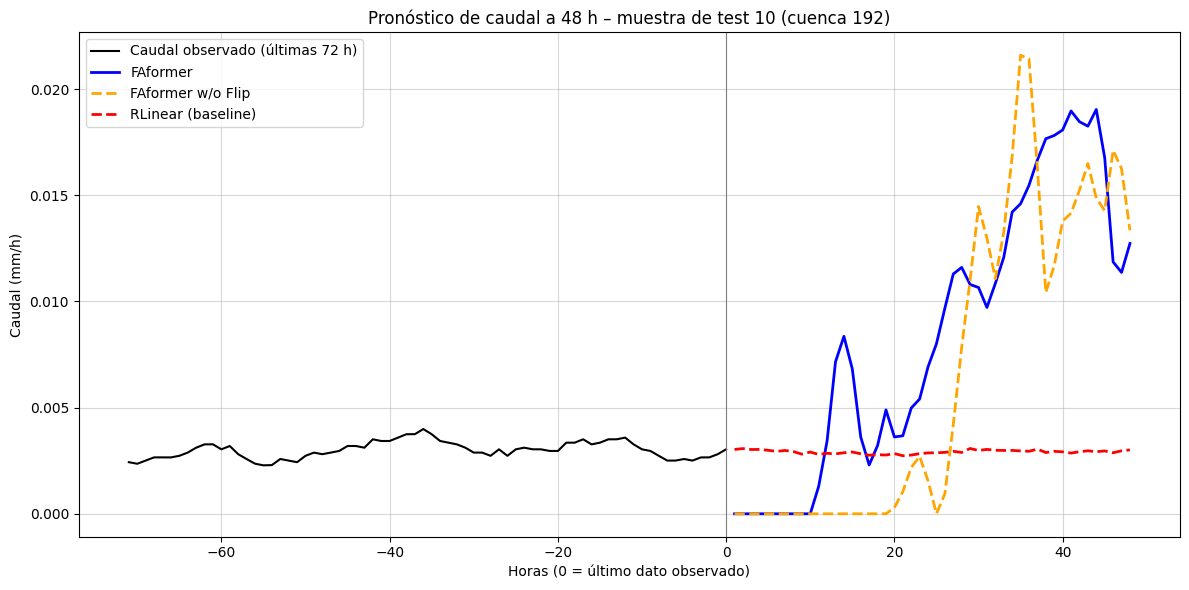

In [10]:
print("Ejecutando inferencia en el conjunto de Test...")
pred_test = {name: predict(m, test_loader) for name, m in best_models.items()}

target_cols = [f'q_{h:02d}' for h in range(1, pred_len + 1)]   # mismo formato que test_targets.csv
file_names = {'FAformer': 'FAformer', 'FAformer w/o Flip': 'FAformer_wo_Flip', 'RLinear (baseline)': 'RLinear'}
for name, p in pred_test.items():
    df = pd.DataFrame(p, columns=target_cols)
    df.insert(0, 'Id', np.arange(len(p)))
    df.to_csv(os.path.join(model_out_path, f'{file_names[name]}_Test_Predictions.csv'), index=False)

print(f"Formato final de predicciones FAformer Test: {pred_test['FAformer'].shape} [Muestras, 48 Horas]")
print(f"✅ Predicciones exportadas a CSV en el directorio: {model_out_path}")

# Gráfica comparativa en test (incluye las últimas 72 h observadas como contexto)
sample_idx = 10
hist_q = X_test[sample_idx, -72:, target_channel] * q_std + q_mean
plt.figure(figsize=(12, 6))
plt.plot(range(-71, 1), hist_q, label='Caudal observado (últimas 72 h)', color='black')
for name, p in pred_test.items():
    plt.plot(range(1, pred_len + 1), p[sample_idx], label=name, color=colors[name],
             linestyle='-' if name == 'FAformer' else '--', linewidth=2)
plt.axvline(0, color='gray', linewidth=0.8)
plt.title(f'Pronóstico de caudal a 48 h – muestra de test {sample_idx} (cuenca {basin_test[sample_idx]})')
plt.xlabel('Horas (0 = último dato observado)')
plt.ylabel('Caudal (mm/h)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

## 10. Evaluación final en test (`test_targets.csv`)

Los valores reales del test se usan **solo aquí**, después de entrenar los modelos con validación, como en el protocolo del paper (test separado).

- Se verifica que los `Id` de `test_targets.csv` coincidan fila a fila con `test.h5`.
- Métricas (media ± desviación entre semillas), ablación en test y comparación validación vs. test.
- Análisis de errores en test y el evento de mayor caudal.

Targets de test: (27983, 48) | caudal máx. 16.280 mm/h (validación: 12.208 mm/h)

Métricas en test (media ± desviación entre semillas; MSE/MAE/NSE en mm/h; *_norm en la escala del paper):


,MSE,MAE,NSE,MSE_norm,MAE_norm
modelo,,,,,
FAformer,0.01135 ± 0.00010,0.03043 ± 0.00132,0.59442 ± 0.00370,0.43211 ± 0.00394,0.18778 ± 0.00812
FAformer w/o Flip,0.01152 ± 0.00010,0.03186 ± 0.00161,0.58837 ± 0.00340,0.43855 ± 0.00362,0.19659 ± 0.00991
RLinear (baseline),0.01184 ± 0.00002,0.02435 ± 0.00008,0.57687 ± 0.00067,0.45081 ± 0.00072,0.15025 ± 0.00051



--- Ablación en test ---


,Δ MSE,MSE: ¿clara?,Δ MAE,MAE: ¿clara?,Δ NSE,NSE: ¿clara?
FAformer w/o Flip,+1.49 %,no (dentro del ruido),+4.69 %,no (dentro del ruido),-0.0061,no (dentro del ruido)



Comparación validación vs test (medias entre semillas):


,MSE val,MSE test,MAE val,MAE test,NSE val,NSE test
modelo,,,,,,
FAformer,0.01196,0.01135,0.02857,0.03043,0.59397,0.59442
FAformer w/o Flip,0.01199,0.01152,0.02983,0.03186,0.59273,0.58837
RLinear (baseline),0.01301,0.01184,0.02273,0.02435,0.55807,0.57687


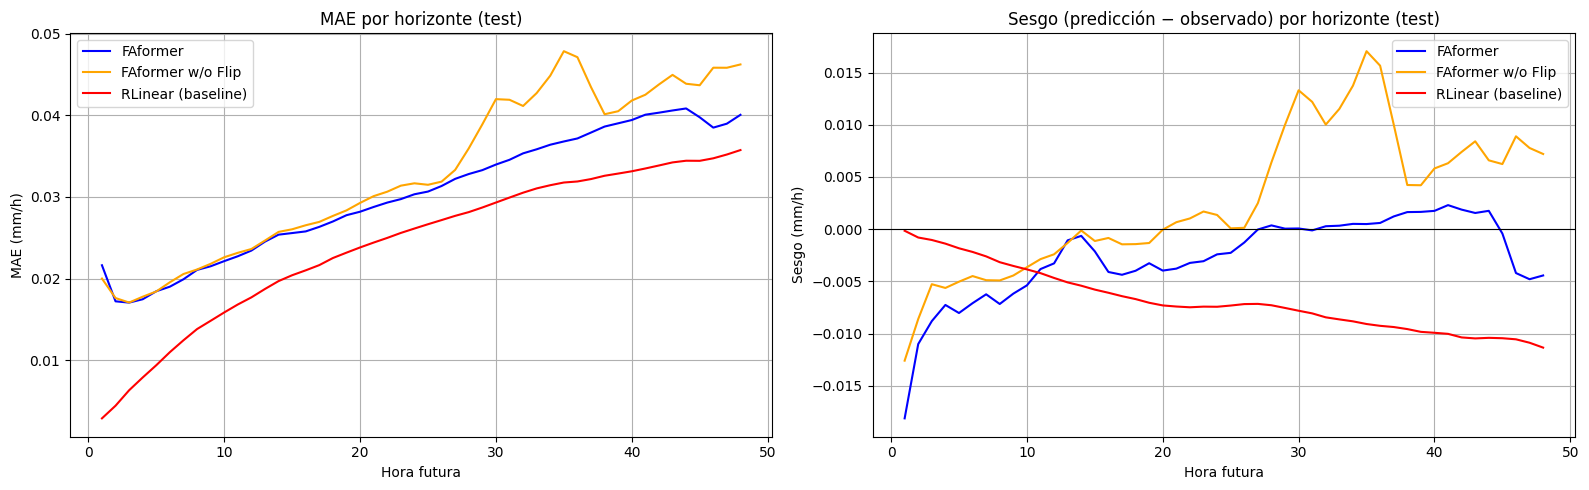

Cuencas evaluadas en test (≥ 10 muestras): 508
NSE por cuenca (la mediana es más representativa que la media, sensible a cuencas de caudal casi constante):


,25%,50%,75%,cuencas con NSE < −1
FAformer,0.1326,0.4850,0.7414,37
FAformer w/o Flip,0.0862,0.4404,0.7091,41
RLinear (baseline),0.2291,0.5738,0.7873,3


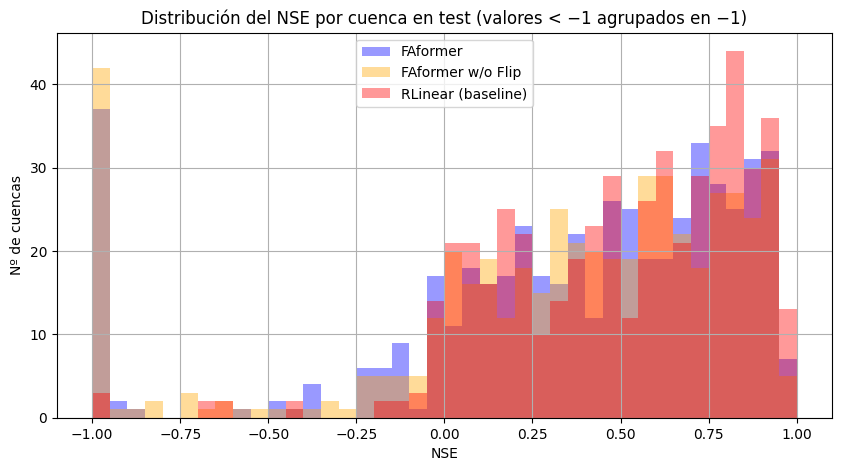

Cuencas con peor NSE para FAformer (test):


,FAformer,FAformer w/o Flip,RLinear (baseline)
378,-311.6993,-922.6741,0.8023
369,-220.9381,-605.2409,-0.0190
188,-139.3610,-649.8075,-4.9291
301,-94.2667,-253.7449,-0.0215
468,-72.7573,-172.6188,0.0152
53,-46.8205,-157.6275,-0.0421
17,-45.4544,-82.6943,0.4855
269,-22.0767,-35.7939,0.7611
398,-21.0537,-68.9957,0.1491
434,-19.2375,-72.8095,0.8212


Error por rango de caudal observado en test (mm/h):


,MAE < p50,MAE p50–p90,MAE p90–p99,MAE > p99 (picos),Sesgo < p50,Sesgo p50–p90,Sesgo p90–p99,Sesgo > p99 (picos)
FAformer,0.0093,0.0270,0.0989,0.5933,0.0030,0.0095,-0.0279,-0.5447
FAformer w/o Flip,0.0125,0.0300,0.0969,0.6028,0.0075,0.0161,-0.0237,-0.5393
RLinear (baseline),0.0023,0.0185,0.1063,0.6182,0.0013,0.0047,-0.0406,-0.5730


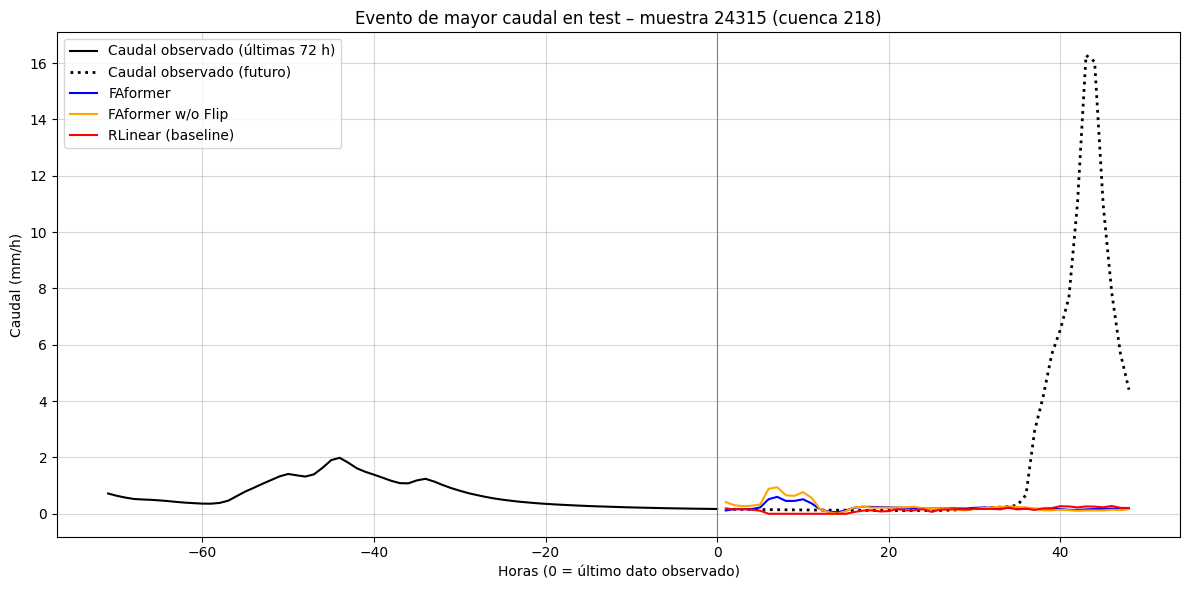

In [11]:
# Valores reales del test: SOLO para la evaluación final (nunca para entrenar ni seleccionar modelos)
targets = pd.read_csv(os.path.join(base_path, 'test_targets.csv')).sort_values('Id')
assert np.array_equal(targets['Id'].to_numpy(), np.arange(len(X_test))), \
    "Los Id de test_targets.csv no coinciden con las filas de test.h5"
y_test_mmh = targets[target_cols].to_numpy(dtype=np.float32)
print(f"Targets de test: {y_test_mmh.shape} | caudal máx. {y_test_mmh.max():.3f} mm/h (validación: {y_val_mmh.max():.3f} mm/h)")

# Métricas en test (todas las semillas)
test_long = per_seed_metrics(test_loader, y_test_mmh)
test_long.to_csv(os.path.join(model_out_path, 'metricas_test_semillas.csv'), index=False)
test_agg, test_table = summarize(test_long)
test_table.to_csv(os.path.join(model_out_path, 'metricas_test.csv'))
print("\nMétricas en test (media ± desviación entre semillas; MSE/MAE/NSE en mm/h; *_norm en la escala del paper):")
display(test_table)

print("\n--- Ablación en test ---")
abl_test = ablation_table(test_agg)
abl_test.to_csv(os.path.join(model_out_path, 'ablacion_test.csv'))
display(abl_test)

# Validación vs test (medias entre semillas)
df_gen = pd.DataFrame({'MSE val': val_agg[('MSE', 'mean')], 'MSE test': test_agg[('MSE', 'mean')],
                       'MAE val': val_agg[('MAE', 'mean')], 'MAE test': test_agg[('MAE', 'mean')],
                       'NSE val': val_agg[('NSE', 'mean')], 'NSE test': test_agg[('NSE', 'mean')]})
print("\nComparación validación vs test (medias entre semillas):")
display(df_gen.style.format('{:.5f}'))

# Análisis de errores en test
nse_basin_test, rangos_test = error_analysis(pred_test, y_test_mmh, basin_test, 'test')

# Evento de mayor caudal del test (limitación en crecidas extremas)
peak_idx = int(np.argmax(y_test_mmh.max(axis=1)))
hist_q = X_test[peak_idx, -72:, target_channel] * q_std + q_mean
plt.figure(figsize=(12, 6))
plt.plot(range(-71, 1), hist_q, label='Caudal observado (últimas 72 h)', color='black')
plt.plot(range(1, pred_len + 1), y_test_mmh[peak_idx], label='Caudal observado (futuro)', color='black', linestyle=':', linewidth=2)
for name, p in pred_test.items():
    plt.plot(range(1, pred_len + 1), p[peak_idx], label=name, color=colors[name])
plt.axvline(0, color='gray', linewidth=0.8)
plt.title(f'Evento de mayor caudal en test – muestra {peak_idx} (cuenca {basin_test[peak_idx]})')
plt.xlabel('Horas (0 = último dato observado)')
plt.ylabel('Caudal (mm/h)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()